# Статистика и честные графики
Данные времени ответа синтетические; единица — минута.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "data").is_dir(), "Откройте блокнот из папки комплекта"
sys.path.insert(0, str(ROOT))
import pandas as pd
from analysis import basic, independent_basic, normalized, export_basic

import matplotlib.pyplot as plt
(ROOT / "outputs").mkdir(exist_ok=True)

In [2]:
times = pd.Series([1,2,3,4,90],name="Время ответа, мин.")
print("mean:",times.mean(),"median:",times.median(),"p90 linear:",times.quantile(.9,interpolation="linear"))

mean: 20.0 median: 3.0 p90 linear: 55.60000000000001


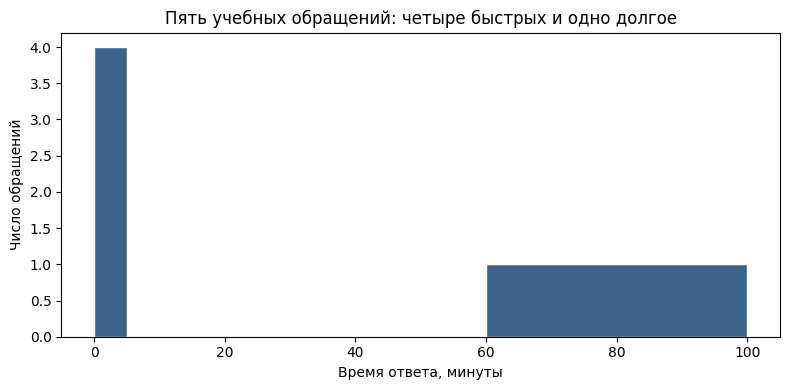

In [3]:
fig,ax = plt.subplots(figsize=(8,4))
ax.hist(times,bins=[0,5,30,60,100],edgecolor="white",color="#3c638c")
ax.set_xlabel("Время ответа, минуты");ax.set_ylabel("Число обращений")
ax.set_title("Пять учебных обращений: четыре быстрых и одно долгое")
fig.tight_layout();fig.savefig(ROOT / "outputs/histogram.png",dpi=160)
plt.show()

In [4]:
buyers = pd.Series([10,9]);visits = pd.Series([100,10])
print("wrong mean:",(buyers/visits).mean())
print("overall:",buyers.sum()/visits.sum())

wrong mean: 0.5
overall: 0.17272727272727273


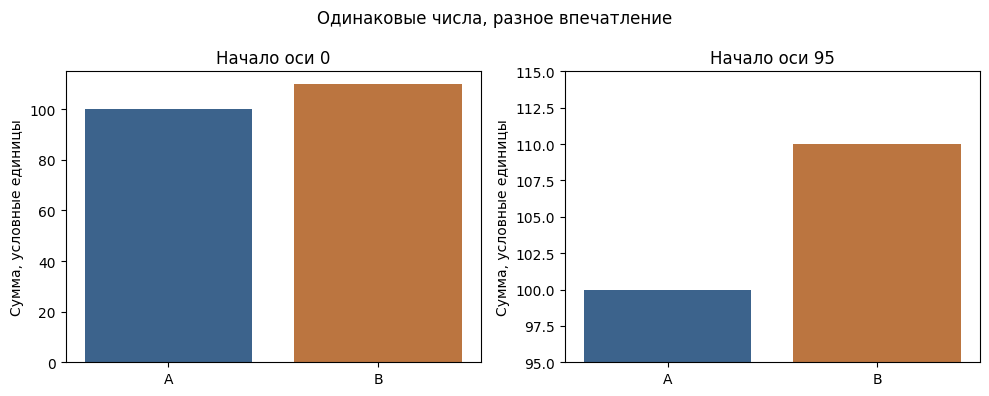

In [5]:
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,low in zip(axes,[0,95]):
    ax.bar(["A","B"],[100,110],color=["#3c638c","#bb7540"])
    ax.set_ylim(low,115);ax.set_ylabel("Сумма, условные единицы")
    ax.set_title("Начало оси " + str(low))
fig.suptitle("Одинаковые числа, разное впечатление")
fig.tight_layout();fig.savefig(ROOT / "outputs/axes.png",dpi=160)
plt.show()

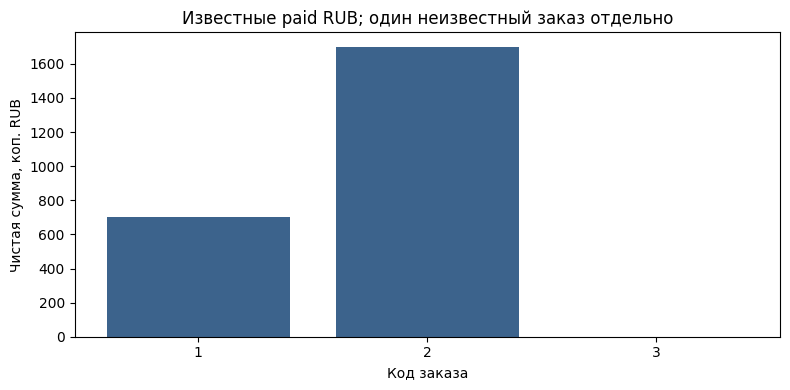

In [6]:
df = basic(ROOT)
fig,ax=plt.subplots(figsize=(8,4))
x=df.dropna(subset=["net_cents"])
ax.bar(x.order_id,x.net_cents,color="#3c638c")
ax.set_xlabel("Код заказа");ax.set_ylabel("Чистая сумма, коп. RUB")
ax.set_title("Известные paid RUB; один неизвестный заказ отдельно")
fig.tight_layout();fig.savefig(ROOT / "outputs/orders-chart.png",dpi=160)
plt.show()

## Ограничение
Нельзя говорить, что медиана описывает все обращения, или что сумма известных заказов — полный оборот. Измените одно значение и подтвердите пересчёт графика. Напишите текстовое описание наблюдения.